# Conditional WGAN-GP on CelebA, conditioned on blond hair

**Course.** Generative AI with Large Language Models, MSAI-630-M41, University of the Cumberlands, Fall 2026 residency.

**Assignment.** Build a conditional GAN on the faces dataset, conditioned on the blond-hair attribute. Change `train_step` so the label matches the generator's input and the critic's input. Turn in the code, the output of the run, and a reading of that output.

**Source of the network.** David Foster, *Generative Deep Learning*, 2nd edition, notebook `notebooks/04_gan/03_cgan/cgan.ipynb` ([GitHub](https://github.com/davidADSP/Generative_Deep_Learning_2nd_Edition/blob/main/notebooks/04_gan/03_cgan/cgan.ipynb)). That notebook is adapted from Sayak Paul's Keras conditional-GAN tutorial. The generator, the critic, and the Wasserstein loss with gradient penalty are that design. The label expansion in `train_step` is the change this residency asks for, and it is the step that was executed.

The runnable modules are `cgan.py`, `data_celeba.py`, `train.py`, and `evaluate.py`. This notebook prints the training step, checks the shapes, and shows the samples from the run that was actually trained.


## 1. The two label formats, and the line that has to change

CelebA stores `Blond_Hair` as −1 or +1. The positive class is +1. Everything else is the negative class. The one-hot used here is the notebook's:

| Class | Meaning | One-hot |
| --- | --- | --- |
| 0 | not blond | `[1, 0]` |
| 1 | blond | `[0, 1]` |

The generator and the critic do not take that vector in the same shape.

- **Generator.** A noise vector of width 32, concatenated with the 2-class vector, reshaped to `(1, 1, 34)`, then transposed convolutions up to a 64×64 RGB image in `[−1, 1]`.
- **Critic.** The 64×64 RGB image, concatenated on the channel axis with the same label repeated at every pixel. That second input is a map of shape `(64, 64, 2)`, not a vector of shape `(2,)`.

`train_step` is where the vector becomes the map. Passing `one_hot_labels` straight into the critic is the mismatch: the critic was built for a spatial map, and a vector of length 2 does not have one. The fix does not invent a new label. It copies the vector the generator just saw onto every pixel, and it uses that same map for the real image, the generated image, and the gradient penalty. If the penalty saw a different label than the two scores, the penalty would not match the critic step it is regularizing.

Labels are joined to files by image id (`000001.jpg` and so on). A list of labels passed to `image_dataset_from_directory` lines up only when the directory walk happens to follow the attribute file. Joining on the filename keeps `Blond_Hair` on the face it belongs to.


In [1]:
import inspect

from cgan import ConditionalWGAN, expand_label_to_map, build_critic, build_generator

print(inspect.getsource(expand_label_to_map))
print(inspect.getsource(ConditionalWGAN.train_step))


def expand_label_to_map(one_hot_labels, image_size=IMAGE_SIZE):
    """Broadcast a class vector into the critic's spatial label map.

    Generator label: (batch, CLASSES) one-hot vector.
    Critic label: (batch, image_size, image_size, CLASSES), the same
    one-hot value at every pixel, later concatenated onto the RGB image.

    Passing one_hot_labels straight into the critic is a rank mismatch
    and is the train_step bug this function removes. No new label is
    invented here; each pixel is a copy of the vector the generator saw.
    """
    label_map = one_hot_labels[:, None, None, :]
    label_map = tf.repeat(label_map, repeats=image_size, axis=1)
    label_map = tf.repeat(label_map, repeats=image_size, axis=2)
    return label_map

    def train_step(self, data):
        # Model.fit resets these at each epoch. This run calls train_step
        # directly, so reset here and the logged value is this update.
        self.c_loss_metric.reset_state()
        self.c_wass_loss_metr

## 2. The networks, and a shape check of the fix

The summaries are the course architecture. The generator's second input is `(None, 2)`. The critic's second input is `(None, 64, 64, 2)`. The cell after the summaries feeds the critic a raw one-hot and then the expanded map.


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf
from cgan import BATCH_SIZE, Z_DIM, build_cgan, expand_label_to_map

cgan = build_cgan()
cgan.generator.summary()
cgan.critic.summary()

images = tf.random.uniform((4, 64, 64, 3))
one_hot = tf.constant([[1.0, 0.0], [0.0, 1.0], [1.0, 0.0], [0.0, 1.0]])
label_map = expand_label_to_map(one_hot)

print("generator one-hot", tuple(one_hot.shape))
print("critic label map", tuple(label_map.shape))
print("corner pixel equals the vector", bool(tf.reduce_all(label_map[:, 0, 0, :] == one_hot)))
print("opposite corner equals the vector", bool(tf.reduce_all(label_map[:, -1, -1, :] == one_hot)))

try:
    cgan.critic([images, one_hot], training=False)
    print("unexpanded vector was accepted")
except Exception as error:
    print("unexpanded vector rejected")
    print(f"{type(error).__name__}: {error}")

scores = cgan.critic([images, label_map], training=False)
fake = cgan.generator([tf.random.normal((4, Z_DIM)), one_hot], training=False)
print("generator image", tuple(fake.shape))
print("critic score", tuple(scores.shape))


Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 32)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_3       │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 34)        │          0 │ input_layer_2[0]… │
│ (Concatenate)       │                   │            │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 34)  │          0 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 4, 4, 128) │     69,632 │ reshape[0][0]     │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 4, 4, 128) │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_4       │ (None, 4, 4, 128) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 8, 8, 128) │    262,144 │ leaky_re_lu_4[0]… │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 128) │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_5       │ (None, 8, 8, 128) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 16, 16,    │    262,144 │ leaky_re_lu_5[0]… │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_6       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_3  │ (None, 32, 32,    │    131,072 │ leaky_re_lu_6[0]… │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_7       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_4  │ (None, 64, 64, 3) │      3,075 │ leaky_re_lu_7[0]… │
│ (Conv2DTranspose)   │                   │            │                 

 Total params: 729,859 (2.78 MB)

 Trainable params: 728,963 (2.78 MB)

 Non-trainable params: 896 (3.50 KB)

Model: "critic"

... (2 outputs left out)

 Trainable params: 662,977 (2.53 MB)

 Non-trainable params: 0 (0.00 B)

generator one-hot (4, 2)
critic label map (4, 64, 64, 2)
corner pixel equals the vector True
opposite corner equals the vector True
unexpanded vector rejected
ValueError: Input 1 with name 'input_layer_1' of layer 'critic' is incompatible with the layer: expected shape=(None, 64, 64, 2), found shape=(4, 2)


generator image (4, 64, 64, 3)
critic score (4, 1)


## 3. The run

Training followed the notebook's schedule rather than a shortened one. `EPOCHS = 20` and `fit(..., epochs=EPOCHS * 100, steps_per_epoch=1)` is 2,000 generator updates, each on a batch of 128, with 3 critic steps and a gradient-penalty weight of 10. Adam uses learning rate `5e-5`, `beta_1 = 0.5`, `beta_2 = 0.9` (the notebook assigns `beta_2` twice; the second value, 0.9, is the one that takes effect).

The notebook sets `run_eagerly=True` so a reader can step through `train_step`. The arithmetic in the cell above is that step. This run traced it, which is what let 2,000 updates finish. The alpha in the penalty is the notebook's normal draw, not the uniform draw from the WGAN-GP paper.

The data are all 202,599 aligned CelebA faces, resized to 64×64 with bilinear interpolation, the same resize `image_dataset_from_directory` performs. Pixels are scaled to `[−1, 1]` to match `tanh`.


In [3]:
import json
from pathlib import Path

import numpy as np

metadata = json.loads(Path("output/run_metadata.json").read_text())
rates = json.loads(Path("output/attribute_base_rates.json").read_text())
history = np.genfromtxt("output/history.csv", delimiter=",", names=True)

print(json.dumps(metadata, indent=2))
print()
print(
    f"images seen: {metadata['steps'] * metadata['batch_size']:,} "
    f"({metadata['steps'] * metadata['batch_size'] / metadata['images']:.2f} passes)"
)
print(f"critic updates: {metadata['steps'] * metadata['critic_steps']:,}")
print()
print("Blond_Hair correlates in the attribute file")
for name, row in rates["correlates"].items():
    print(
        f"  {name:16}  P(attr | blond)={row['P_given_blond']:.3f}"
        f"   P(attr | not blond)={row['P_given_not_blond']:.3f}"
    )
print()
wass = history["c_wass_loss"]
gp = history["c_gp"]
print(f"Wasserstein estimate: most negative {wass.min():.1f} at step {wass.argmin() + 1}")
print(f"Wasserstein estimate, last 100 updates: mean {wass[-100:].mean():.2f}")
print(f"gradient penalty, last 100 updates: mean {gp[-100:].mean():.3f}")


{
  "label": "Blond_Hair",
  "class_0": "not blond, one-hot [1, 0], CelebA attribute != 1",
  "class_1": "blond, one-hot [0, 1], CelebA attribute == 1",
  "images": 202599,
  "blond_images": 29983,
  "blond_rate": 0.14799184596172735,
  "image_size": 64,
  "z_dim": 32,
  "batch_size": 128,
  "steps": 2000,
  "critic_steps": 3,
  "gp_weight": 10.0,
  "learning_rate": 5e-05,
  "adam_beta_1": 0.5,
  "adam_beta_2": 0.9,
  "seed": 42,
  "minutes": 72.56,
  "filenames_in_attribute_file": 202599
}

images seen: 256,000 (1.26 passes)
critic updates: 6,000

Blond_Hair correlates in the attribute file
  Male              P(attr | blond)=0.058   P(attr | not blond)=0.479
  Heavy_Makeup      P(attr | blond)=0.675   P(attr | not blond)=0.337
  Pale_Skin         P(attr | blond)=0.071   P(attr | not blond)=0.038
  Attractive        P(attr | blond)=0.698   P(attr | not blond)=0.480
  Smiling           P(attr | blond)=0.590   P(attr | not blond)=0.463
  Black_Hair        P(attr | blond)=0.000   P(attr 

## 4. Output

Real faces first, so the label has a visible meaning. Then the same ten noise vectors at the start of training and at the end. Then fresh samples from the saved generator, the real-against-generated board, and the paired difference.

The paired grids keep the noise fixed down each column. The only change from the top row to the bottom row is the one-hot: `[1, 0]` then `[0, 1]`.


**Real faces, not blond. CelebA `Blond_Hair` is not +1.**

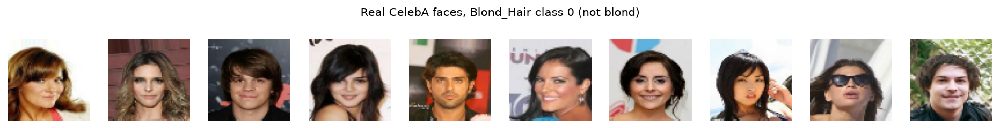

**Real faces, blond. CelebA `Blond_Hair` is +1.**

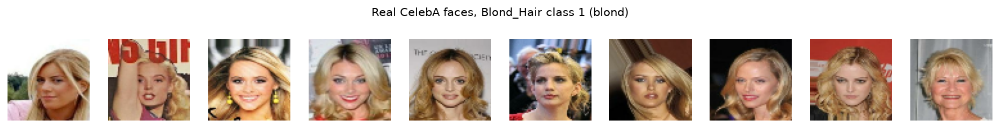

**Step 0. Both labels are a flat gray field. Nothing has been learned, and the rows match.**

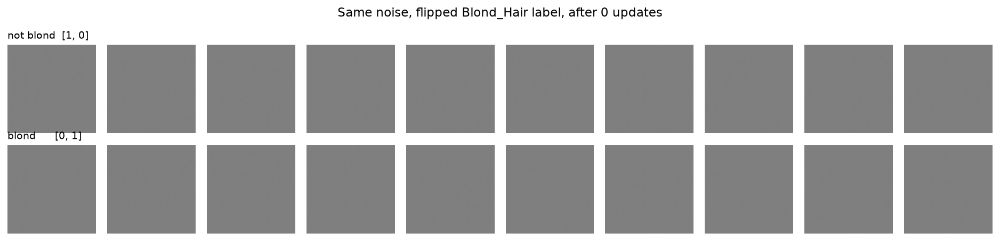

**Step 400. Skin-colored blobs, a darker cap where hair will be. The rows are still hard to tell apart.**

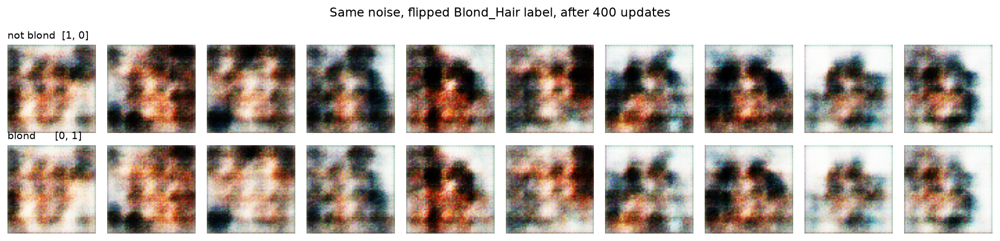

**Step 1000. A face layout: oval, hair region, lighter background. Still blurry.**

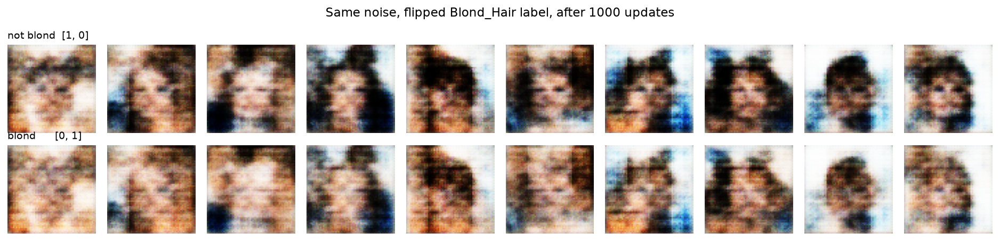

**Step 2000. Same ten noise vectors. The blond row is lighter and softer. Pose does not get redrawn.**

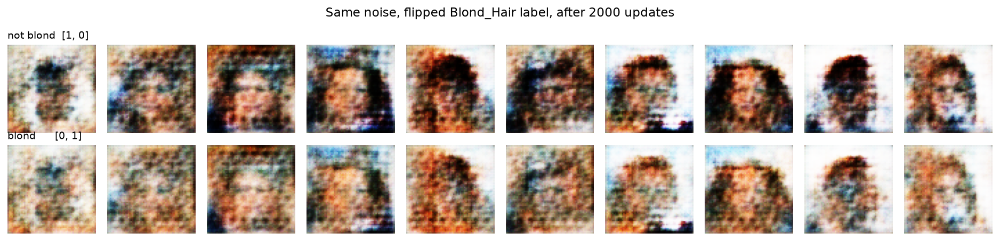

**Loss over the 2,000 updates.**

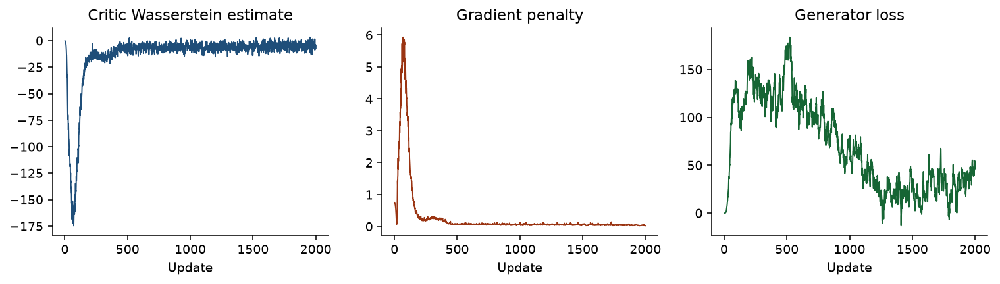

**Final paired samples from the saved generator. Same noise, label flipped.**

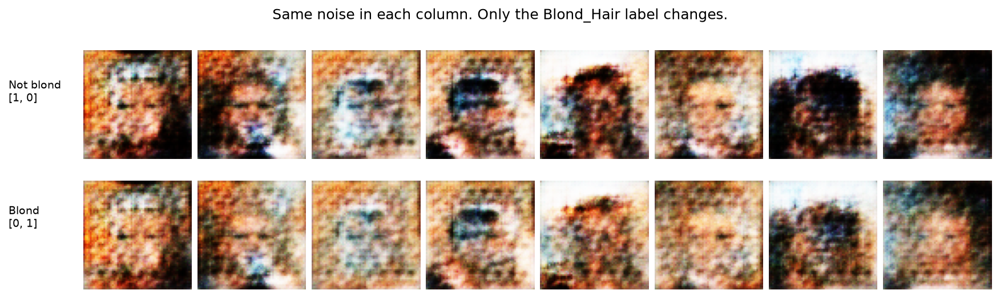

**Class 0 samples, not blond.**

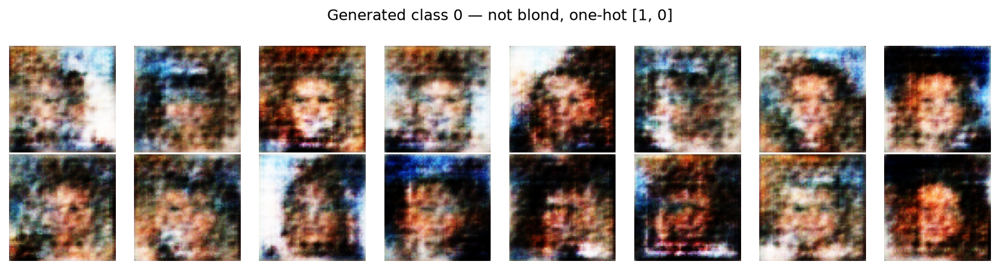

**Class 1 samples, blond.**

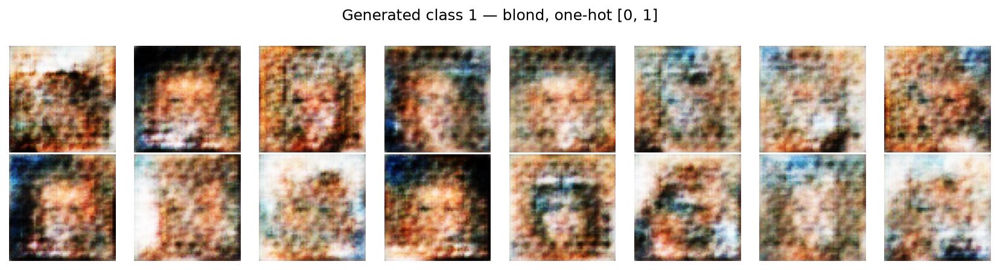

**Real photographs beside generated samples of the same label.**

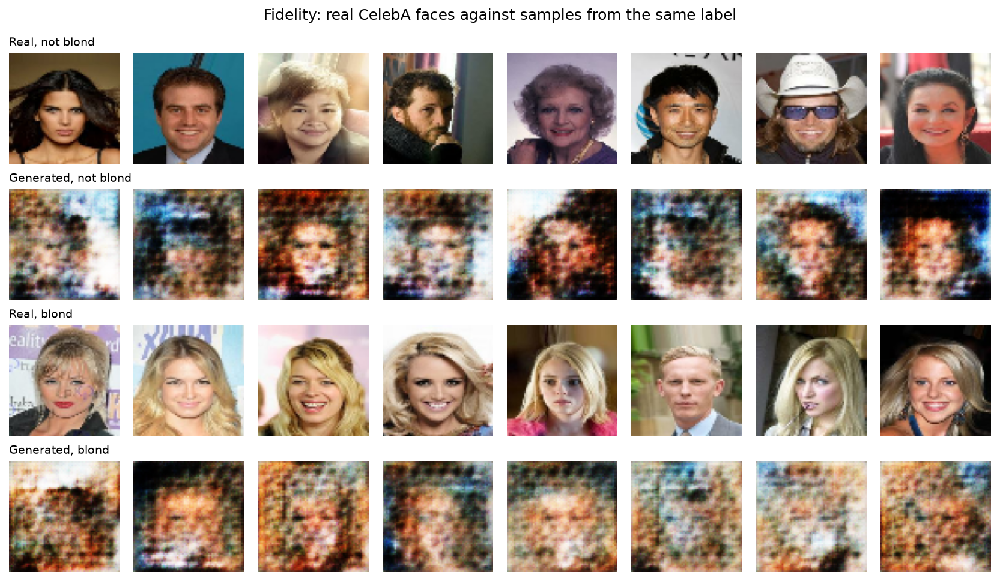

**Boxes used for the luminance proxy. Yellow is the hair band. Blue is the center of the face.**

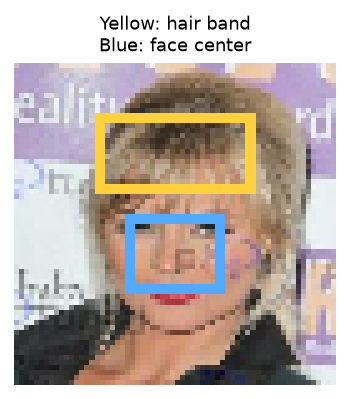

**Average paired difference. Red means the blond label made that pixel brighter.**

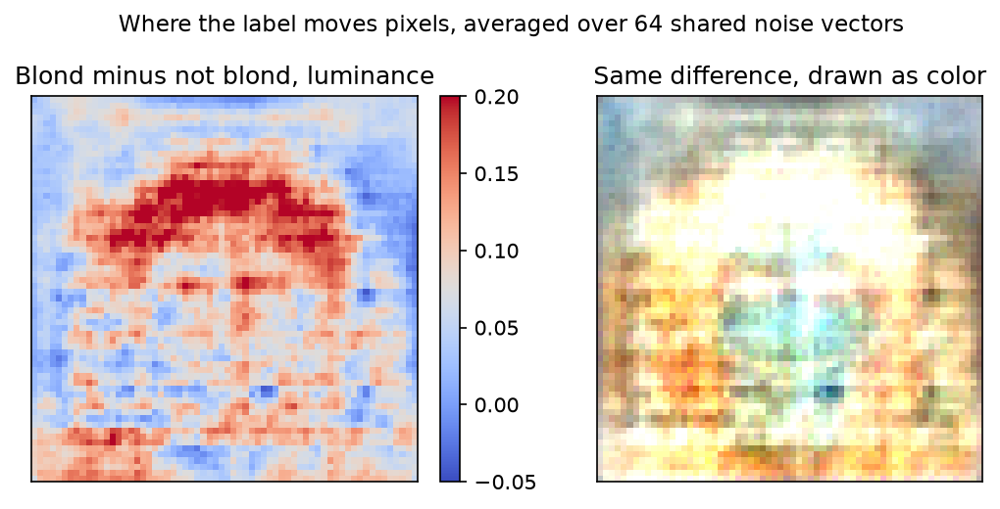

**Hair-band gap against the face-center gap, over 64 shared noise vectors.**

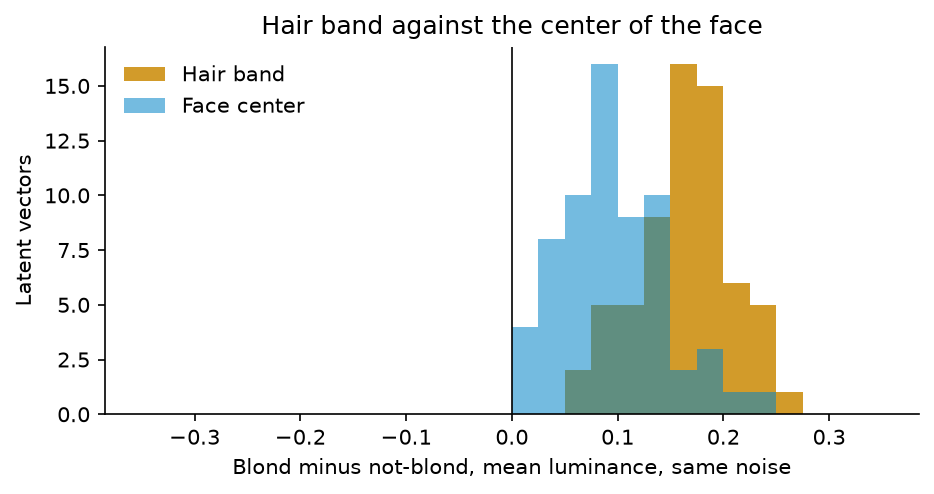

In [4]:
from IPython.display import Image, Markdown, display

figures = [
    ("Real faces, not blond. CelebA `Blond_Hair` is not +1.", "output/real_not_blond.png"),
    ("Real faces, blond. CelebA `Blond_Hair` is +1.", "output/real_blond.png"),
    ("Step 0. Both labels are a flat gray field. Nothing has been learned, and the rows match.", "output/paired_step_0000.png"),
    ("Step 400. Skin-colored blobs, a darker cap where hair will be. The rows are still hard to tell apart.", "output/paired_step_0400.png"),
    ("Step 1000. A face layout: oval, hair region, lighter background. Still blurry.", "output/paired_step_1000.png"),
    ("Step 2000. Same ten noise vectors. The blond row is lighter and softer. Pose does not get redrawn.", "output/paired_step_2000.png"),
    ("Loss over the 2,000 updates.", "output/loss_curves.png"),
    ("Final paired samples from the saved generator. Same noise, label flipped.", "output/final_paired.png"),
    ("Class 0 samples, not blond.", "output/final_not_blond.png"),
    ("Class 1 samples, blond.", "output/final_blond.png"),
    ("Real photographs beside generated samples of the same label.", "output/real_vs_generated.png"),
    ("Boxes used for the luminance proxy. Yellow is the hair band. Blue is the center of the face.", "output/measurement_boxes.png"),
    ("Average paired difference. Red means the blond label made that pixel brighter.", "output/label_difference_map.png"),
    ("Hair-band gap against the face-center gap, over 64 shared noise vectors.", "output/label_luminance_gap.png"),
]
for caption, path in figures:
    display(Markdown(f"**{caption}**"))
    display(Image(filename=path))


In [5]:
evaluation = json.loads(Path("output/evaluation.json").read_text())
print(json.dumps(evaluation, indent=2))


{
  "classes": {
    "not_blond": {
      "fake_pairwise_rmse": 0.359,
      "real_pairwise_rmse": 0.3745,
      "fake_pixel_std": 0.2497,
      "real_pixel_std": 0.2638,
      "fake_hair_mean": 0.3448,
      "real_hair_mean": 0.3756,
      "fake_face_mean": 0.4999,
      "real_face_mean": 0.5427
    },
    "blond": {
      "fake_pairwise_rmse": 0.3197,
      "real_pairwise_rmse": 0.3623,
      "fake_pixel_std": 0.221,
      "real_pixel_std": 0.252,
      "fake_hair_mean": 0.5024,
      "real_hair_mean": 0.5097,
      "fake_face_mean": 0.5885,
      "real_face_mean": 0.6108
    }
  },
  "difference_rgb": {
    "hair_rgb_blond_minus_not": [
      0.1988,
      0.1696,
      0.1209
    ],
    "face_rgb_blond_minus_not": [
      0.0848,
      0.1135,
      0.088
    ]
  },
  "paired_label_flip": {
    "n": 64,
    "hair_mean_blond_minus_not": 0.1631,
    "hair_gap_positive_fraction": 1.0,
    "face_mean_blond_minus_not": 0.0954,
    "face_gap_positive_fraction": 1.0
  },
  "real_unpaired_

## 5. Observations about the output and its accuracy

The pictures above are the 2,000-update run, not a longer one. This network, for this long, does not produce photographs. The reading does not treat it as if it had.

Three questions are worth separating, because a GAN can pass one and fail the others. Fidelity: do the samples look like faces? Diversity: did the generator collapse onto one picture? Conditioning: does the blond-hair label actually control the sample?

### Fidelity

At step 0 both labels emit a flat gray square. Batch normalization is still at its zero initialization, and `tanh(0)` is gray, so the two rows match and neither is a face.

By step 400 the samples are skin-colored blobs with a darker mass along the top. By step 1,000 there is a face layout: a warmer oval, a region where hair sits, a lighter surround. At step 2,000 that layout is steadier and still soft. Eyes, teeth, ears, and individual hair strands are not there. Next to the real CelebA photographs, these would not be mistaken for pictures of people.

The curves say the blur is unfinished learning, not a diverged update. The critic's Wasserstein estimate fell to about −175 at step 71 and the gradient penalty spiked, which is the critic pulling ahead of a generator that is still emitting mush. Both then recovered. Over the last 100 updates the Wasserstein gap averages about −4.7, and the gradient penalty averages about 0.04. A penalty near zero means the critic's input gradients are near unit length, which is the constraint this loss is there to enforce. The generator loss is a poor quality number on its own. The critic has no squashing nonlinearity, so its raw score can sit far from zero while the gap between real and fake stays modest. That gap, and the samples, are the evidence.

One quantity did land close to the data. In the hair band, generated not-blond faces average luminance 0.345 against 0.376 for real not-blond faces, and generated blond faces average 0.502 against 0.510 for real blond faces. The hair region is about the right brightness. It is not yet hair.

### Diversity

The sample grids are not one image copied across the row. Where the head sits, how dark the cap is, and what the background does all change from column to column.

The average root-mean-square distance between distinct samples, on pixels scaled to [0, 1], is close to the same distance on real faces:

| Class | Generated pairwise RMSE | Real pairwise RMSE |
| --- | ---: | ---: |
| Not blond | 0.359 | 0.375 |
| Blond | 0.320 | 0.362 |

Not-blond samples are about as spread out as real not-blond faces. Blond samples are tighter, roughly 88% of the real blond spread, and they look softer. That fits a class that is only 14.8% of the data. It is not mode collapse. Collapse would drive the pairwise distance toward zero and make every column the same picture. Neither class does that.

### Conditioning

A single pair is not enough to say the control works. In the step-2,000 grid the bottom row is the same noise as the top row. Pose stays put, which is what a conditional model should do, but many columns look like the same blur with the contrast lowered. If the test is whether a person can call the hair color from one sample, this run fails it. The faces are too soft, and the blond row is "lighter" more than it is "blond."

The label is not being ignored. That shows up when the same comparison is averaged over noise instead of judged from one lucky column.

On 64 shared noise vectors, the hair band was brighter under the blond label every time. The mean gap is +0.163 on a 0-to-1 scale. The center of the face was also brighter every time, by less: +0.095. No tested latent moved in the wrong direction. The histogram is entirely to the right of zero, with the hair-band mass sitting to the right of the face-center mass.

The extra hair brightness is warm. Those 64 pairs move the hair band by about +0.199 red, +0.170 green, and +0.121 blue. The face center moves by about +0.085 red, +0.114 green, and +0.088 blue. Hair shifts toward yellow. The face shift does not.

The average difference image is the spatial version of that sentence. The bright pixels form an arch across the hair. The face changes less. The side background goes slightly the other way. A label that only turned up a global brightness knob would be a flat field. This is not a flat field.

Real CelebA, measured with the same two boxes, goes the same direction: blond faces are +0.134 brighter in the hair band and +0.068 brighter in the face center. The generator's gaps, +0.163 and +0.095, are a bit larger and in the same order. The hair-band means themselves, quoted in the fidelity section, already sit within a few hundredths of the real class means.

So the control moved hair luminance in the blond direction, on every latent that was tested, and it moved hair more than it moved the face. That is partial evidence that the condition was learned. It is not evidence that blond-hair control works as a switch.

Two properties of the label block a stronger claim. Blond is 14.8% of the set, so most critic updates are the negative class, and the blond grid is the blurrier of the two. Blond is also tied to other attributes. In this file, 5.8% of blond faces are labeled male, against 47.9% of the remaining faces, and 67.5% of blond faces are labeled heavy makeup, against 33.7%. A network can score well by drifting toward a lighter, smoother face. The hair-shaped difference is the reason to think the model caught more than that correlate. The face-center shift, and the makeup and gender imbalance, are the reason not to treat it as isolated hair control. CelebA's own tag is noisy at the boundary: plenty of light-brown hair is stored as not blond, so the generator cannot be cleaner than the label.

### What would convince you the condition was learned

The comparison that matters uses one noise vector and both labels, so pose is not free to change, and then asks for something sharper than "the picture got brighter."

- On recognizable faces, a person who has not seen the label should be able to name the hair color clearly above chance.
- A classifier trained only on real `Blond_Hair` labels should score generated blond samples well above the not-blond samples from the same noise.
- The paired difference should stay on the hair. A difference that lights up the jaw, the makeup, or the whole frame is the correlate, not the attribute.

This run meets a weak form of the third test. The average paired difference is a warmer arch on the hair, and the hair gap is larger than the face gap. It does not meet the first test. The samples are too blurred for a person to call the color from one image, and no external classifier was used. The pictures support a directional, partial effect. They do not support a claim that the blond-hair control is accurate yet.

### Bottom of the rubric, in one paragraph

The code builds the conditional WGAN-GP from the course notebook, conditions it on `Blond_Hair`, and expands the generator's one-hot into the critic's label map inside `train_step`. The shape check shows the unexpanded vector being rejected and the map being accepted, with every pixel equal to the vector. The output of 2,000 updates is a stable training run whose samples have a face layout, have not collapsed, and respond to the blond label with a reliable warm shift on the hair. The samples are not yet faces, and the label is not yet a clean hair-color control.


## 6. How to rerun

CelebA is not in the repository. Its license is non-commercial research use, from the Multimedia Lab at the Chinese University of Hong Kong. Place `list_attr_celeba.txt` and `img_align_celeba/` under `data/`, then:

```bash
pip install -r requirements.txt
python train.py --steps 2000
python evaluate.py
```

`output/run_metadata.json` records the step count, the class balance, and the wall-clock time of the run shown above. The generator weights that produced the final figures are `models/generator.weights.h5`.
